# Computing Project 
## 3-Particle Quantum Mechanics

### varying $\kappa$ parameter

#### Connecting to kernel

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [1]:
print('connected')

connected


In [3]:
import numpy as np
import scipy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.special import factorial
# import pandas



#### Defining things

In [47]:
electron_charge = 14.4 ##eVA this is the squared value
r0 = 0.52917 ##A

In [48]:
hyll_states = [[0,0,0], [0,0,1], [0,2,0]]
one_state_basis = [[0,0,0]]


chosen_states = hyll_states
chosen_num = len(chosen_states)

In [43]:

def all(kap, en, staytes):
    def generate_matrix(kappa, n, states):
        zed = 2
        r_0_ang = 0.52917 ## Angstrom
        hy_lambda = zed /(kappa * r_0_ang)
        hbar = sc.constants.hbar
        electron_mass = sc.constants.m_e

        mat_N = [[0]*n for _ in range(n)]
        mat_W = [[0]*n for _ in range(n)]
        mat_C = [[0]*n for _ in range(n)]
        mat_T = [[0]*n for _ in range(n)]

        for i in range(n): #this will give the number of rows
            for j in range(n):  # this will give the number of cols

                j_1 = states[i][0]  
                j_2 = states[j][0]
                k_1 = states[i][1] 
                k_2 = states[j][1]
                m_1 = states[i][2] 
                m_2 = states[j][2]

                jay = states[i][0] + states[j][0]
                kay = states[i][1] + states[j][1]
                em = states[i][2] + states[j][2]


                def N(J, K, M):
                    if M == -2:
                        entry_value_N = 0
                    else:   
                        factorial_term = factorial((J + K + M +5), exact = True) #if this needs to be faster, set exact to be false
                        wavelength_term = (1/(2*hy_lambda))**((J+K+M+6))
                        coeff = (2*(np.pi)**2) / (M+2)
                        fraction_sum = (1/(K+1) - 1/(K+3) - 1/(K+M+3) + 1/(K+M+5))
                
                        if K%2 ==0:
                            entry_value_N = factorial_term * coeff * wavelength_term * fraction_sum
                        if K%2 ==1:
                            entry_value_N = 0
                    return entry_value_N
                
                def W(J, K, M):
                    
                    value = (electron_charge)*(N(jay, kay, em-1))
                    
                    return value
                

                def C(J, K, M):
                    if M == -2:
                        entry_value_C = 0
                    else:   
                        factorial_term = factorial((J + K + M +4), exact = True) #if this needs to be faster, set exact to be false
                        wavelength_term = (1/(2*hy_lambda))**((J+K+M+5))
                        coeff = (8*(np.pi)**2) / (M+2)
                        fraction_sum = (1/(K+1) - 1/(K+M+3))
                        extra_pre = -zed * electron_charge
                
                        if K%2 ==0:
                            entry_value_C = extra_pre * factorial_term * coeff * wavelength_term * fraction_sum
                        if K%2 ==1:
                            entry_value_C = 0
                    return entry_value_C
                
                
                def T(J, K, M, j1, j2, k1, k2, m1, m2):


                    coeff = (hbar**2)/(2*electron_mass)
                    square_1 = (
                        (hy_lambda**2)*N(jay, kay, em) 
                        - J*hy_lambda*N(jay-1, kay, em) 
                        + j1*j2*N(jay-2, kay, em) 
                        + k1*k2*N(jay,kay-2, em)
                        + m1*m2*N(jay, kay, em-2) 
                    )
                    square_2 = (
                        -M*hy_lambda*(C(jay, kay, em) - C(jay, kay+2, em-2))
                        +(m1*j2 + m2*j1)*(C(jay-1, kay, em) - C(jay-1, kay+2, em-2))
                        +(m1*k2 + m2*k1)*(C(jay+1, kay, em-2)-C(jay-1,kay, em))
                    )
                    value = coeff* (
                        2*square_1 + 0.5*square_2
                    )
                    return value
                
                    

                mat_N[i][j] = N(jay, kay, em)
                mat_W[i][j] = W(jay, kay, em)
                mat_C[i][j] = C(jay, kay, em)
                mat_T[i][j] = T(jay, kay, em, j_1, j_2, k_1, k_2, m_1, m_2)
        

        matrices = [mat_N, mat_W, mat_C, mat_T]
        return matrices

    N_mat, W_mat, C_mat, T_mat= generate_matrix(kap, en, staytes)

    def find_eig(matrix):
        values, vectors = sc.linalg.eig(matrix)
        # values.sort()
        
        return [values, vectors]

    def generate_eig_mats(matrix, n):
        eig_vals, eig_vects = find_eig(matrix)
        diag = [[0]*n for _ in range(n)]
        for i in range(n):
            for j in range(n):
                if i==j:
                    diag[i][j]= float(eig_vals[i])
        return [diag, eig_vects]
    beta, Y_mat = generate_eig_mats(N_mat, en)
    Y_mat_tr = Y_mat.transpose()

    def raise_mat_to_power(matrix, power):
        
        length = len(matrix)
        assert length == len(matrix[0]) #checks square matrix

        new_mat = [[0]* length for _ in range(length)]

        for i in range(length):
            for j in range(length):
                if i!=j:
                    assert matrix[i][j] == 0
                if i==j:
                    new_mat[i][j] = (matrix[i][j])**power
        
        return new_mat

    beta_half_p = np.asarray(raise_mat_to_power(beta, 0.5))
    beta_half_m = np.asarray(raise_mat_to_power(beta, -0.5))

    def create_H(T, C, W):
        n = len(T)
        H = [[0]* n for _ in range(n)]
        for i in range(n):
            for j in range(n):
                H[i][j] = T[i][j] + C[i][j] + W[i][j]
        return H

    H_mat = np.asarray(create_H(T_mat, C_mat, W_mat))

    def find_energy(B_m, H, Y, YT):
        P = B_m @ YT @ H @ Y @ B_m

        energies, _ = sc.linalg.eig(P)
        energies.sort()

        energy = energies[-1]
        
        return float(energy)
        
    
    answer = find_energy(beta_half_m, H_mat, Y_mat, Y_mat_tr)
    return answer





In [44]:
print(all(1, chosen_num, chosen_states))

-105.74952484079944


In [45]:
kappas = np.arange(-2, 2, 0.1)
print(len(kappas))

40


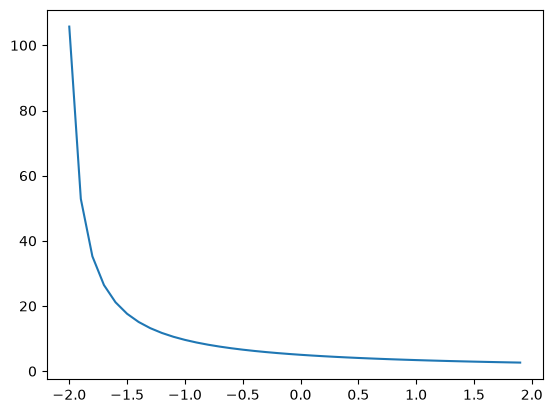

In [46]:
energies = []
for kap in range(len(kappas)+1):
    if kap != 0 :
        energies.append(abs(all(kap, chosen_num, chosen_states)))
    else:
        kap+= 0.001

# print(energies)

plt.plot(kappas, energies)